# LAB CHƯƠNG 2 — XỬ LÝ ẢNH SỐ

Notebook thực hiện các yêu cầu của Lab Chương 2: toán tử điểm ảnh, lọc tuyến tính, phát hiện cạnh, kernel tự thiết kế, so sánh bộ lọc và lọc phi tuyến tính.

**Chuẩn bị ảnh:** tự tạo/đặt ảnh của bạn trong thư mục `input/` nằm cùng cấp với notebook. Notebook không tải ảnh từ Internet và không kèm ảnh mẫu. Nếu thư mục chỉ có một ảnh hợp lệ, notebook tự nhận ảnh đó. Nếu có nhiều ảnh, chọn tên ảnh tại biến `IMAGE_FILENAME` ở phần 1.

**Đầu ra:** tất cả ảnh kết quả được lưu trong thư mục `results/`.


## 0. Cài đặt thư viện

Cần Python cùng các thư viện `opencv-python`, `numpy`, `matplotlib`. Nếu máy chưa có, bỏ dấu `#` ở dòng `%pip install` trong cell kế tiếp rồi chạy cell đó.


In [1]:
# %pip install opencv-python numpy matplotlib

import cv2
import numpy as np
import matplotlib.pyplot as plt
import time
from pathlib import Path

SEED = 42
OUTPUT_DIR = Path("results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"OpenCV: {cv2.__version__}")
print(f"NumPy: {np.__version__}")
print(f"Thư mục kết quả: {OUTPUT_DIR.resolve()}")


OpenCV: 5.0.0
NumPy: 2.5.4
Thư mục kết quả: D:\python\Computer Vision\lab2\results


## 1. Đọc ảnh do người dùng cung cấp

1. Đặt ảnh cần xử lý vào thư mục `input/` (cùng cấp với notebook).
2. Nếu `input/` chỉ có một ảnh, notebook tự chọn ảnh đó.
3. Nếu có nhiều ảnh, nhập chính xác tên file vào `IMAGE_FILENAME` ở cell tiếp theo.

Hỗ trợ các định dạng phổ biến: PNG, JPG/JPEG, BMP, TIFF và WEBP. Không có ảnh mẫu hoặc tải ảnh tự động.


In [2]:
# Thư mục chứa ảnh do bạn tự thêm.
INPUT_DIR = Path("input")
INPUT_DIR.mkdir(parents=True, exist_ok=True)

# Để None nếu trong input/ chỉ có một ảnh.
# Nếu có nhiều ảnh, ví dụ: IMAGE_FILENAME = "hinh_cua_toi.jpg"
IMAGE_FILENAME = None

SUPPORTED_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}
available_images = sorted(
    p for p in INPUT_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in SUPPORTED_EXTENSIONS
)

if not available_images:
    raise FileNotFoundError(
        f"Chưa có ảnh trong thư mục '{INPUT_DIR}'. "
        "Hãy chép một file ảnh vào input/ rồi chạy lại notebook."
    )

if IMAGE_FILENAME is None:
    if len(available_images) != 1:
        names = "\n".join(f"- {p.name}" for p in available_images)
        raise ValueError(
            "Có nhiều ảnh trong input/. Hãy đặt IMAGE_FILENAME bằng tên ảnh muốn dùng.\n"
            f"Các ảnh hiện có:\n{names}"
        )
    image_path = available_images[0]
else:
    image_path = INPUT_DIR / IMAGE_FILENAME
    if not image_path.is_file():
        raise FileNotFoundError(f"Không tìm thấy ảnh: {image_path}")
    if image_path.suffix.lower() not in SUPPORTED_EXTENSIONS:
        raise ValueError(f"Định dạng ảnh không được hỗ trợ: {image_path.suffix}")

# Đọc ảnh Unicode-safe trên Windows.
image = cv2.imdecode(np.fromfile(str(image_path), dtype=np.uint8), cv2.IMREAD_COLOR)
if image is None:
    raise ValueError(f"Không đọc được ảnh '{image_path}'. Hãy kiểm tra file ảnh.")

height, width = image.shape[:2]
print(f"Ảnh đầu vào: {image_path}")
print(f"Kích thước: {width} x {height} | Kiểu dữ liệu: {image.dtype}")


Ảnh đầu vào: input\images.jpg
Kích thước: 554 x 554 | Kiểu dữ liệu: uint8


In [3]:
if image.ndim != 3 or image.shape[2] != 3:
    raise ValueError("Ảnh đầu vào phải là ảnh màu 3 kênh BGR.")

print("Đã nạp ảnh thành công. Các phần tiếp theo sẽ dùng chung ảnh này.")


Đã nạp ảnh thành công. Các phần tiếp theo sẽ dùng chung ảnh này.


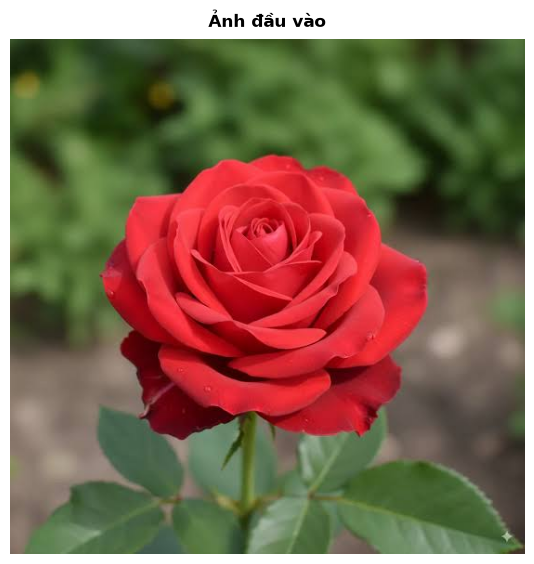

In [4]:
def show_images(items, cols=3, figsize=(16, 10), title_size=12):
    """Hiển thị ảnh theo lưới; mỗi ảnh có tiêu đề rõ ràng."""
    rows = int(np.ceil(len(items) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax in axes.flat:
        ax.axis("off")

    for ax, item in zip(axes.flat, items):
        title, data, *cmap = item
        ax.imshow(
            data,
            cmap=cmap[0] if cmap else None,
            vmin=0 if cmap else None,
            vmax=255 if cmap else None,
        )
        ax.set_title(title, fontsize=title_size, fontweight="bold", pad=9)
        ax.axis("off")

    fig.tight_layout(pad=2.0)
    plt.show()


def to_rgb(bgr):
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def save_image(filename, img):
    """Lưu ảnh, hỗ trợ đường dẫn Unicode."""
    path = OUTPUT_DIR / filename
    ext = path.suffix or ".png"
    ok, encoded = cv2.imencode(ext, img)
    if not ok:
        raise IOError(f"Không mã hóa được ảnh: {path}")
    encoded.tofile(str(path))
    return path


def center_crop(img, ratio=0.35):
    """Cắt vùng trung tâm để quan sát chi tiết; giữ cùng vùng cho mọi ảnh."""
    h, w = img.shape[:2]
    crop_h = max(1, int(h * ratio))
    crop_w = max(1, int(w * ratio))
    y1 = (h - crop_h) // 2
    x1 = (w - crop_w) // 2
    return img[y1:y1 + crop_h, x1:x1 + crop_w]


show_images([("Ảnh đầu vào", to_rgb(image))], cols=1, figsize=(10, 6))

## 2. Toán tử điểm ảnh

Thực hiện tăng/giảm độ sáng, tăng/giảm tương phản, âm bản và cắt ngưỡng. Các phép biến đổi được tính trên từng pixel; kết quả được giới hạn trong miền `[0, 255]`.

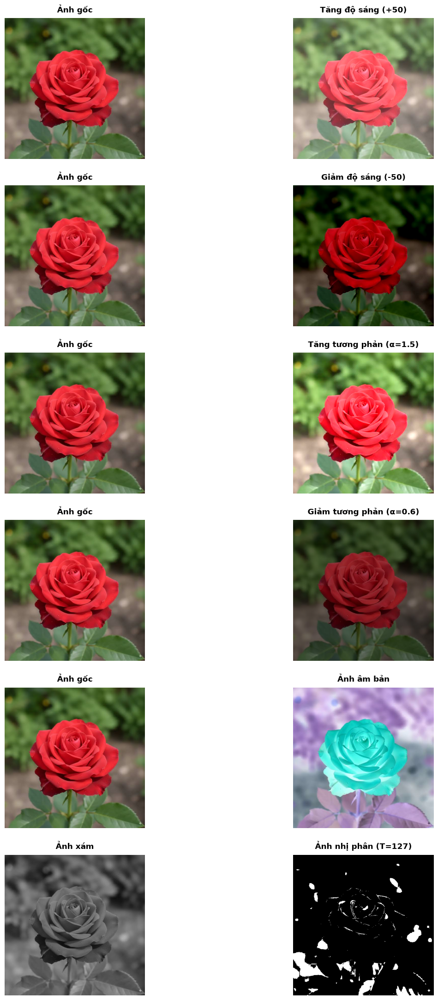

In [5]:
# 2.1 Độ sáng: cộng/trừ hằng số trên từng kênh.
brightness_delta = 50
bright = np.clip(image.astype(np.int16) + brightness_delta, 0, 255).astype(np.uint8)
dark = np.clip(image.astype(np.int16) - brightness_delta, 0, 255).astype(np.uint8)

# 2.2 Độ tương phản: nhân từng pixel với alpha.
contrast_high = np.clip(image.astype(np.float32) * 1.5, 0, 255).astype(np.uint8)
contrast_low = np.clip(image.astype(np.float32) * 0.6, 0, 255).astype(np.uint8)

# 2.3 Âm bản.
negative = 255 - image

# 2.4 Cắt ngưỡng trên ảnh xám.
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
threshold_value = 127
_, binary = cv2.threshold(gray, threshold_value, 255, cv2.THRESH_BINARY)

pixel_results = {
    "brightness_up": bright,
    "brightness_down": dark,
    "contrast_up": contrast_high,
    "contrast_down": contrast_low,
    "negative": negative,
    "threshold": binary,
}
for name, result in pixel_results.items():
    save_image(f"{name}.png", result)

# Hiển thị theo cặp để dễ đối chiếu với ảnh gốc.
show_images([
    ("Ảnh gốc", to_rgb(image)),
    ("Tăng độ sáng (+50)", to_rgb(bright)),
    ("Ảnh gốc", to_rgb(image)),
    ("Giảm độ sáng (-50)", to_rgb(dark)),
    ("Ảnh gốc", to_rgb(image)),
    ("Tăng tương phản (α=1.5)", to_rgb(contrast_high)),
    ("Ảnh gốc", to_rgb(image)),
    ("Giảm tương phản (α=0.6)", to_rgb(contrast_low)),
    ("Ảnh gốc", to_rgb(image)),
    ("Ảnh âm bản", to_rgb(negative)),
    ("Ảnh xám", gray, "gray"),
    (f"Ảnh nhị phân (T={threshold_value})", binary, "gray"),
], cols=2, figsize=(16, 22))

## 3. Lọc tuyến tính

- **Mean:** trung bình đều các pixel trong vùng lân cận.
- **Gaussian:** trung bình có trọng số Gaussian.
- **Sharpen:** kernel làm sắc nét, tăng cường chi tiết và biên.

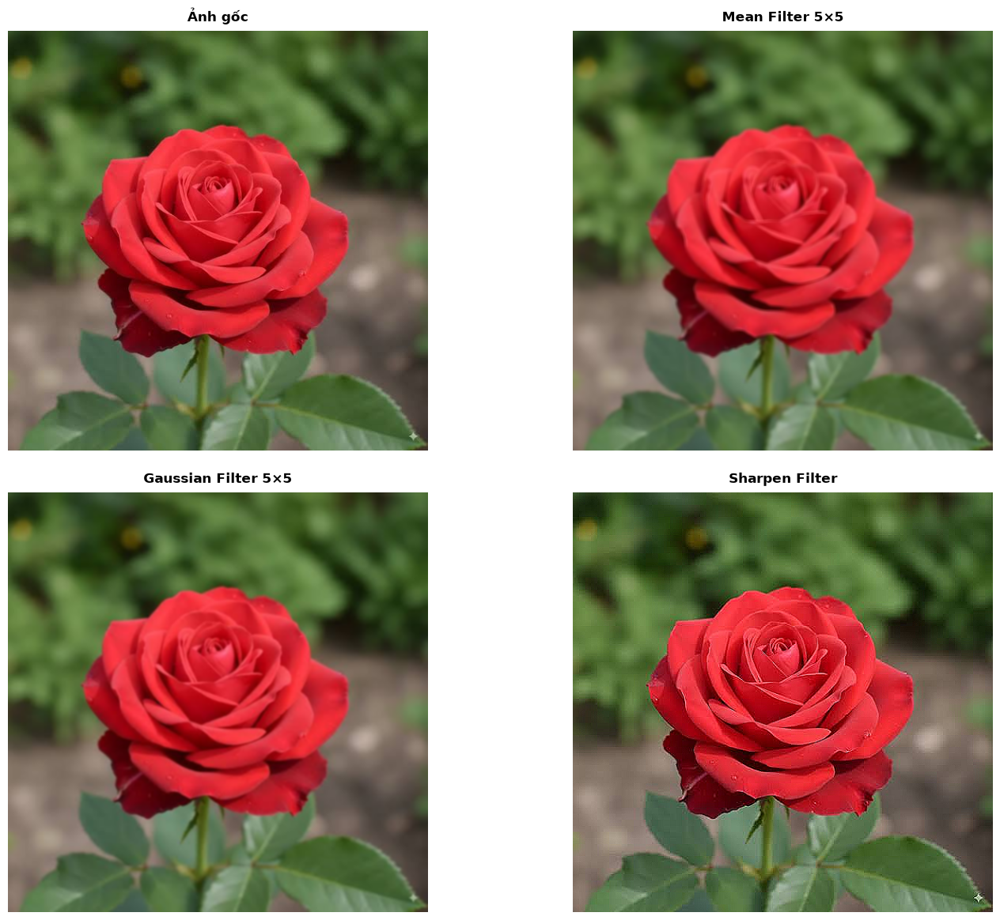

In [6]:
mean_filtered = cv2.blur(image, (5, 5))
gaussian_filtered = cv2.GaussianBlur(image, (5, 5), sigmaX=1.2)
sharpen_kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float32)
sharpened = cv2.filter2D(image, ddepth=-1, kernel=sharpen_kernel)

for name, result in [
    ("mean_5x5.png", mean_filtered),
    ("gaussian_5x5.png", gaussian_filtered),
    ("sharpen.png", sharpened),
]:
    save_image(name, result)

show_images([
    ("Ảnh gốc", to_rgb(image)),
    ("Mean Filter 5×5", to_rgb(mean_filtered)),
    ("Gaussian Filter 5×5", to_rgb(gaussian_filtered)),
    ("Sharpen Filter", to_rgb(sharpened)),
], cols=2, figsize=(16, 12))

## 4. Kernel tự thiết kế

Các kernel minh họa bốn hiệu ứng: làm mờ trung bình, làm sắc nét, phát hiện vùng thay đổi cường độ và emboss.

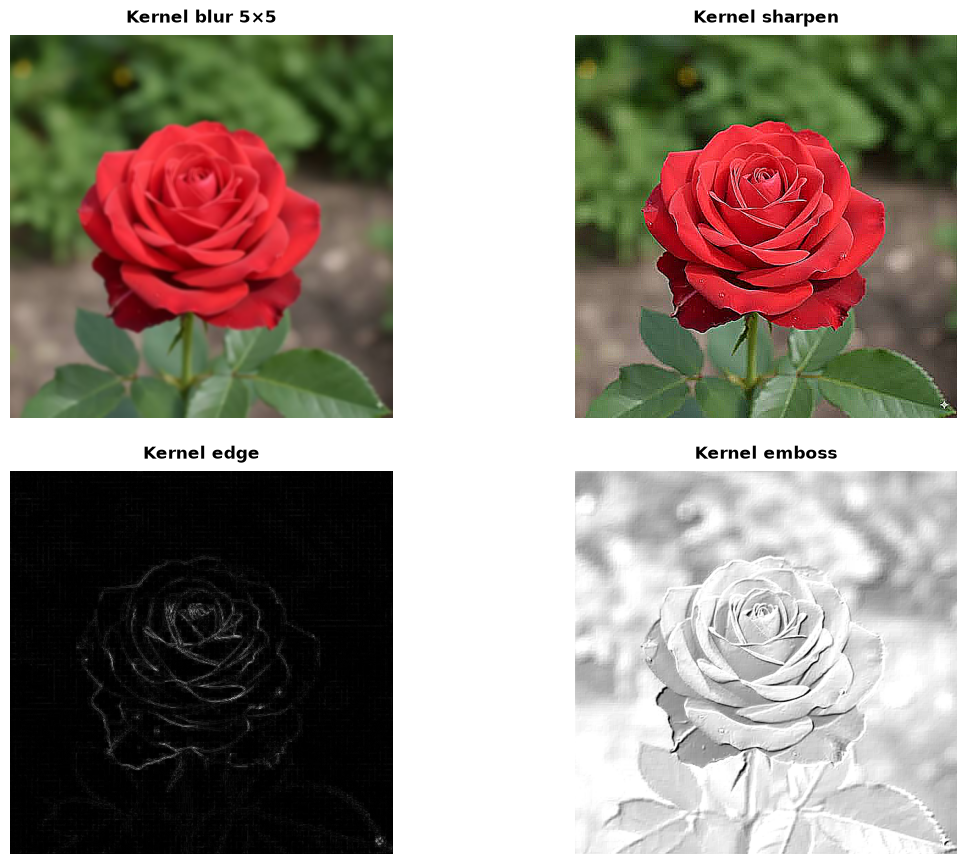

In [7]:
kernel_blur = np.ones((5, 5), dtype=np.float32) / 25
kernel_sharpen_custom = np.array([[-1, -1, -1], [-1, 9, -1], [-1, -1, -1]], dtype=np.float32)
kernel_edge = np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]], dtype=np.float32)
kernel_emboss = np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]], dtype=np.float32)

custom_blur = cv2.filter2D(image, -1, kernel_blur)
custom_sharpen = cv2.filter2D(image, -1, kernel_sharpen_custom)
edge_raw = cv2.filter2D(gray, cv2.CV_32F, kernel_edge)
custom_edge = cv2.normalize(np.abs(edge_raw), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
emboss_raw = cv2.filter2D(gray, cv2.CV_32F, kernel_emboss)
custom_emboss = np.clip(emboss_raw + 128, 0, 255).astype(np.uint8)

for name, result in [("custom_blur.png", custom_blur), ("custom_sharpen.png", custom_sharpen),
                     ("custom_edge.png", custom_edge), ("custom_emboss.png", custom_emboss)]:
    save_image(name, result)

show_images([
    ("Kernel blur 5×5", to_rgb(custom_blur)),
    ("Kernel sharpen", to_rgb(custom_sharpen)),
    ("Kernel edge", custom_edge, "gray"),
    ("Kernel emboss", custom_emboss, "gray"),
], cols=2, figsize=(13, 9))

## 5. Phát hiện cạnh Sobel và Prewitt

Ảnh được chuyển sang grayscale và làm mượt nhẹ trước khi tính gradient. Độ lớn gradient được chuẩn hóa về `[0, 255]` để hiển thị rõ, tránh cắt cụt các giá trị lớn.

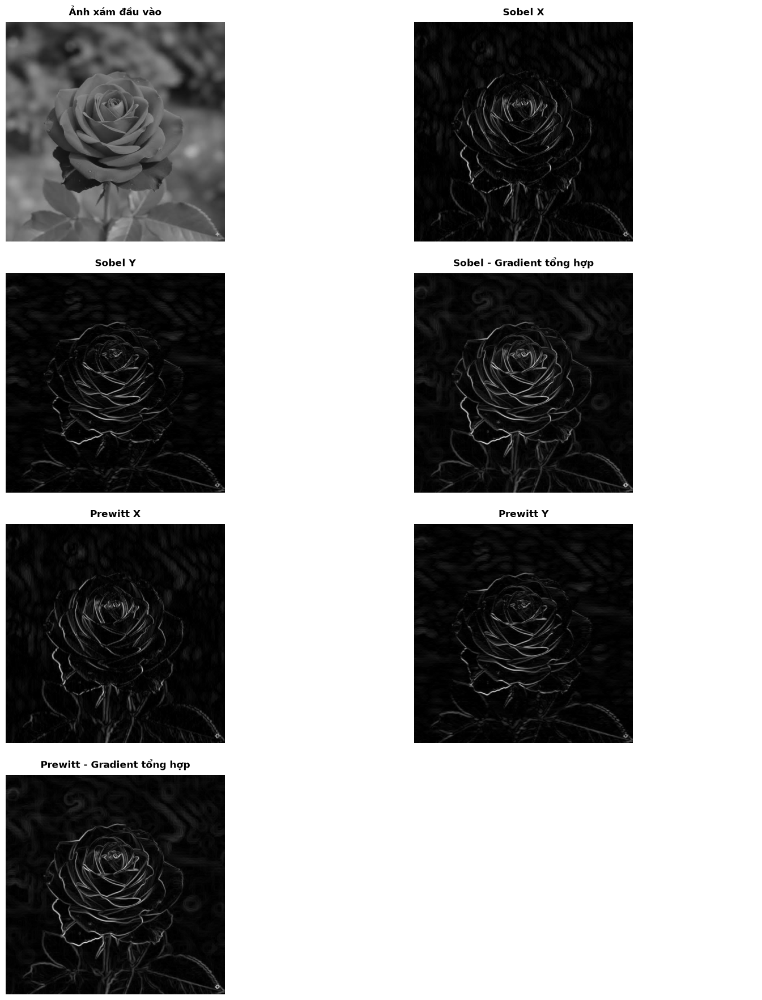

In [8]:
edge_input = cv2.GaussianBlur(gray, (3, 3), 0)

# Sobel
sobel_x = cv2.Sobel(edge_input, cv2.CV_32F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(edge_input, cv2.CV_32F, 0, 1, ksize=3)
sobel_magnitude = cv2.magnitude(sobel_x, sobel_y)
sobel_result = cv2.normalize(sobel_magnitude, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
sobel_x_view = cv2.normalize(np.abs(sobel_x), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
sobel_y_view = cv2.normalize(np.abs(sobel_y), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# Prewitt
prewitt_kernel_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float32)
prewitt_kernel_y = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float32)
prewitt_x = cv2.filter2D(edge_input, cv2.CV_32F, prewitt_kernel_x)
prewitt_y = cv2.filter2D(edge_input, cv2.CV_32F, prewitt_kernel_y)
prewitt_magnitude = cv2.magnitude(prewitt_x, prewitt_y)
prewitt_result = cv2.normalize(prewitt_magnitude, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
prewitt_x_view = cv2.normalize(np.abs(prewitt_x), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
prewitt_y_view = cv2.normalize(np.abs(prewitt_y), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

for name, result in [
    ("sobel_x.png", sobel_x_view), ("sobel_y.png", sobel_y_view),
    ("sobel_magnitude.png", sobel_result), ("prewitt_x.png", prewitt_x_view),
    ("prewitt_y.png", prewitt_y_view), ("prewitt_magnitude.png", prewitt_result),
]:
    save_image(name, result)

show_images([
    ("Ảnh xám đầu vào", gray, "gray"),
    ("Sobel X", sobel_x_view, "gray"),
    ("Sobel Y", sobel_y_view, "gray"),
    ("Sobel - Gradient tổng hợp", sobel_result, "gray"),
    ("Prewitt X", prewitt_x_view, "gray"),
    ("Prewitt Y", prewitt_y_view, "gray"),
    ("Prewitt - Gradient tổng hợp", prewitt_result, "gray"),
], cols=2, figsize=(16, 18))

## 6. Lọc phi tuyến tính và so sánh trực quan, định lượng

Phần này là trọng tâm so sánh của bài lab:

- Tạo **một ảnh nhiễu muối tiêu duy nhất** từ ảnh bạn cung cấp.
- Mean, Gaussian, Median và Bilateral đều xử lý **cùng chính ảnh nhiễu đó**.
- Hiển thị một lưới ảnh toàn cảnh gồm ảnh gốc, ảnh nhiễu và bốn kết quả lọc.
- Hiển thị thêm vùng trung tâm được phóng to với cùng tọa độ cắt để dễ quan sát chi tiết.
- Tính MSE, PSNR và thời gian chạy của từng bộ lọc để hỗ trợ nhận xét.

**Cách đọc:** MSE càng thấp và PSNR càng cao thì kết quả càng gần ảnh gốc theo sai số pixel. Tuy nhiên, không nên chỉ dựa vào hai chỉ số này để kết luận bộ lọc tốt nhất; cần quan sát cả khả năng loại bỏ nhiễu và bảo toàn biên.

SO SÁNH TOÀN ẢNH — TẤT CẢ KẾT QUẢ DÙNG CÙNG MỘT ẢNH NHIỄU


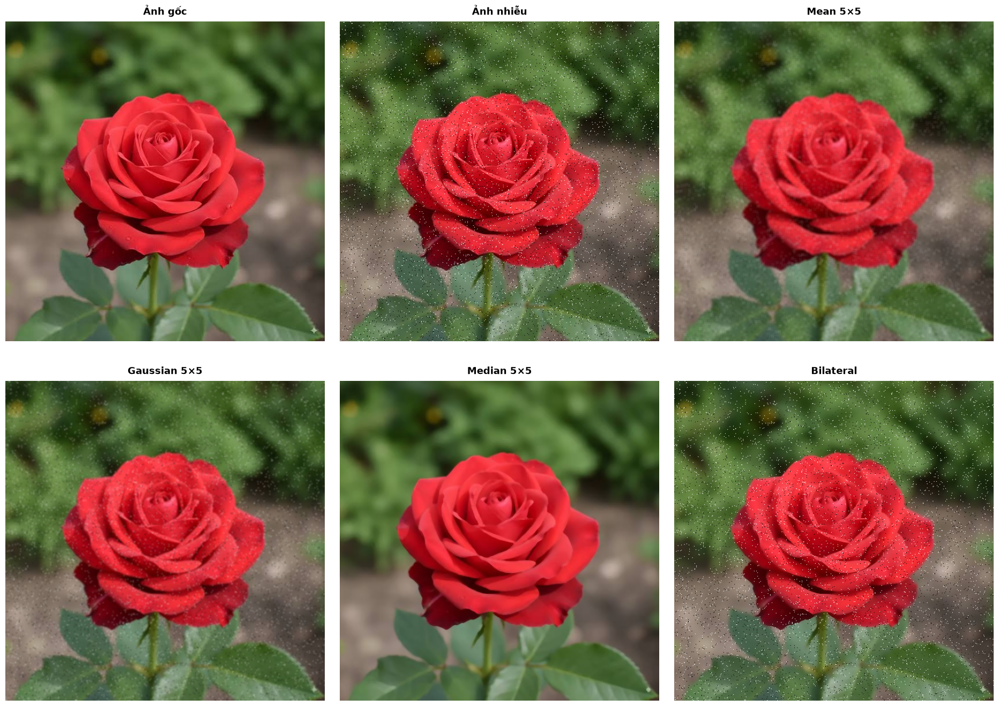

SO SÁNH CHI TIẾT — CÙNG MỘT VÙNG CẮT Ở TẤT CẢ ẢNH


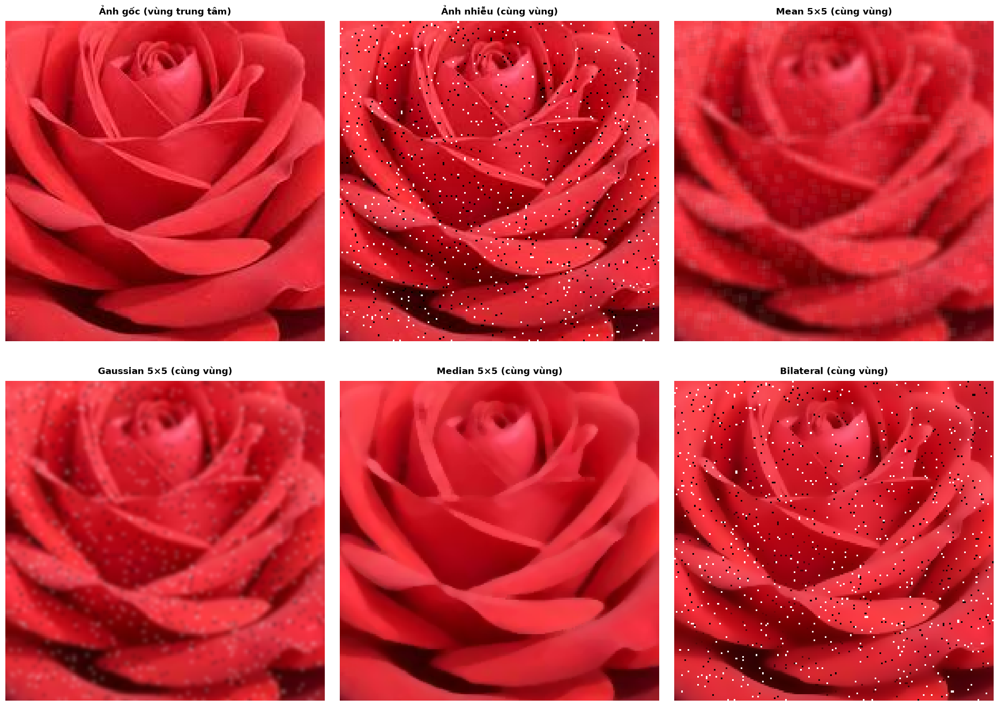

BẢNG ĐÁNH GIÁ ĐỊNH LƯỢNG SO VỚI ẢNH GỐC
Phương pháp                   MSE      PSNR (dB)    Thời gian (ms)
-------------------------------------------------------------------
Ảnh nhiễu                  609.01          20.28              0.00
Mean 5×5                    44.11          31.68              1.03
Gaussian 5×5                50.86          31.07              0.38
Median 5×5                   7.91          39.15              2.43
Bilateral                  590.86          20.42             27.86
PSNR cao nhất: Median 5×5 (39.15 dB)
MSE thấp nhất: Median 5×5 (7.91)
\nLƯU Ý: PSNR/MSE đo mức gần ảnh gốc, không đánh giá đầy đủ độ tự nhiên hay khả năng giữ biên. Hãy kết hợp quan sát toàn ảnh và vùng phóng to.


In [9]:
def add_salt_pepper_noise(img, amount=0.03, seed=SEED):
    """Thêm nhiễu muối tiêu; cùng một ảnh nhiễu được dùng cho mọi bộ lọc."""
    generator = np.random.default_rng(seed)
    noisy = img.copy()
    count = int(amount * img.shape[0] * img.shape[1])
    ys = generator.integers(0, img.shape[0], count)
    xs = generator.integers(0, img.shape[1], count)
    half = count // 2
    noisy[ys[:half], xs[:half]] = 0
    noisy[ys[half:], xs[half:]] = 255
    return noisy


def calculate_mse(reference, candidate):
    difference = reference.astype(np.float32) - candidate.astype(np.float32)
    return float(np.mean(difference ** 2))


def calculate_psnr(reference, candidate):
    return float(cv2.PSNR(reference, candidate))


noisy_image = add_salt_pepper_noise(image, amount=0.03, seed=SEED)

# Mọi bộ lọc nhận chính xác cùng noisy_image.
filter_functions = {
    "Mean 5×5": lambda src: cv2.blur(src, (5, 5)),
    "Gaussian 5×5": lambda src: cv2.GaussianBlur(src, (5, 5), 1.2),
    "Median 5×5": lambda src: cv2.medianBlur(src, 5),
    "Bilateral": lambda src: cv2.bilateralFilter(src, d=9, sigmaColor=75, sigmaSpace=75),
}

comparison = {"Ảnh nhiễu": noisy_image}
filter_times = {}
for name, filter_function in filter_functions.items():
    start_time = time.perf_counter()
    filtered = filter_function(noisy_image)
    filter_times[name] = (time.perf_counter() - start_time) * 1000
    comparison[name] = filtered

# Lưu ảnh gốc, ảnh nhiễu và tất cả kết quả so sánh.
save_image("comparison_original.png", image)
for name, result in comparison.items():
    safe_name = (
        name.lower()
        .replace(" ", "_")
        .replace("×", "x")
    )
    save_image(f"comparison_{safe_name}.png", result)

# 1) So sánh toàn ảnh: Ảnh gốc -> ảnh nhiễu -> kết quả của từng bộ lọc.
overview_items = [("Ảnh gốc", to_rgb(image))]
overview_items += [(name, to_rgb(result)) for name, result in comparison.items()]
print("SO SÁNH TOÀN ẢNH — TẤT CẢ KẾT QUẢ DÙNG CÙNG MỘT ẢNH NHIỄU")
show_images(overview_items, cols=3, figsize=(19, 14), title_size=13)

# 2) Phóng to cùng một vùng trung tâm để quan sát chi tiết.
crop_items = [("Ảnh gốc (vùng trung tâm)", to_rgb(center_crop(image)))]
crop_items += [(f"{name} (cùng vùng)", to_rgb(center_crop(result)))
               for name, result in comparison.items()]
print("SO SÁNH CHI TIẾT — CÙNG MỘT VÙNG CẮT Ở TẤT CẢ ẢNH")
show_images(crop_items, cols=3, figsize=(19, 14), title_size=12)

# 3) Bảng chỉ số định lượng so với ảnh gốc.
# PSNR cao hơn và MSE thấp hơn thường biểu thị kết quả gần ảnh tham chiếu hơn.
metric_rows = []
for name, result in comparison.items():
    metric_rows.append((
        name,
        calculate_mse(image, result),
        calculate_psnr(image, result),
        filter_times.get(name, 0.0),
    ))

print("BẢNG ĐÁNH GIÁ ĐỊNH LƯỢNG SO VỚI ẢNH GỐC")
print(f"{'Phương pháp':<18} {'MSE':>14} {'PSNR (dB)':>14} {'Thời gian (ms)':>17}")
print("-" * 67)
for name, mse, psnr, elapsed in metric_rows:
    print(f"{name:<18} {mse:>14.2f} {psnr:>14.2f} {elapsed:>17.2f}")

best_psnr = max(metric_rows, key=lambda row: row[2])
best_mse = min(metric_rows, key=lambda row: row[1])
print(f"PSNR cao nhất: {best_psnr[0]} ({best_psnr[2]:.2f} dB)")
print(f"MSE thấp nhất: {best_mse[0]} ({best_mse[1]:.2f})")

# 4) Ghi chú để đọc kết quả đúng:
print(
    "\\nLƯU Ý: PSNR/MSE đo mức gần ảnh gốc, không đánh giá đầy đủ độ tự nhiên "
    "hay khả năng giữ biên. Hãy kết hợp quan sát toàn ảnh và vùng phóng to."
)

## 7. Kiểm thử và tổng kết

Cell cuối kiểm tra kích thước, kiểu dữ liệu, miền giá trị và sự tồn tại của các file đầu ra. Nếu có lỗi, notebook sẽ phát sinh exception thay vì báo hoàn thành giả.

In [10]:
# Kiểm tra mọi ảnh xử lý có cùng kích thước và kiểu uint8.
all_results = {
    **pixel_results,
    "mean": mean_filtered,
    "gaussian": gaussian_filtered,
    "sharpen": sharpened,
    "custom_blur": custom_blur,
    "custom_sharpen": custom_sharpen,
    "custom_edge": custom_edge,
    "custom_emboss": custom_emboss,
    "sobel": sobel_result,
    "prewitt": prewitt_result,
    **{f"comparison_{k}": v for k, v in comparison.items()},
}

for name, result in all_results.items():
    assert result.shape[:2] == image.shape[:2], f"Sai kích thước: {name}"
    assert result.dtype == np.uint8, f"Sai dtype: {name} ({result.dtype})"
    assert np.min(result) >= 0 and np.max(result) <= 255, f"Sai miền giá trị: {name}"

saved_files = sorted(p.name for p in OUTPUT_DIR.iterdir() if p.is_file())
assert len(saved_files) >= 20, f"Thiếu file kết quả: chỉ có {len(saved_files)} file"

print("KIỂM THỬ THÀNH CÔNG")
print(f"- Ảnh đầu vào: {width} x {height}")
print(f"- Số kết quả đã kiểm tra: {len(all_results)}")
print(f"- Số file đã lưu: {len(saved_files)}")
print(f"- Thư mục kết quả: {OUTPUT_DIR.resolve()}")

KIỂM THỬ THÀNH CÔNG
- Ảnh đầu vào: 554 x 554
- Số kết quả đã kiểm tra: 20
- Số file đã lưu: 25
- Thư mục kết quả: D:\python\Computer Vision\lab2\results
